# 05 - Logistic purchase-propensity baseline
The project uses **one logistic regression baseline**, retaining the original specification requested by the user. It predicts `purchase_14d` from all 43 registered pre-send predictors. Its probability describes buying under the historical mixture of offers; it is neither treatment-assignment propensity nor an untreated response probability.

The original preprocessing fills missing numeric values, adds missing-value indicators, standardizes numeric inputs, and one-hot encodes categories. Logistic regression uses `C=0.01`. There are **no log transforms, added interactions, or extra probability calibration**. Earlier comparisons with a more complex version remain optional research in `scripts/experiment_propensity.py` and `outputs/experiments/propensity/`; they do not change this baseline.

The headline metrics are **average precision** and **recall at a development-chosen threshold**, accompanied by precision, flagged share, and probability-quality diagnostics. We fit the same specification on earlier campaigns to set its threshold, evaluate it on CP07, and then refit it on all historical campaigns for July. CP07 was previously inspected and the user chose the simpler baseline after reviewing those comparisons, so this is retrospective evaluation, **not a fresh untouched holdout**.


In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.calibration import calibration_curve
from src.common import TABLES, FIGS, MODELS, load_processed
from src.modeling import feature_lists, load_logistic_baseline_config, fit_logistic_baseline
from src.propensity import purchase_metrics, choose_purchase_threshold
pd.set_option("display.width", 200)
df = load_processed("historical_feature_outcome")
NUM, CAT = feature_lists(); X_COLS = NUM + CAT
outcomes = set(pd.read_csv(TABLES / "outcome_schema.csv").outcome)
FORBIDDEN = {"assignment_id", "customer_id", "campaign_id", "send_ts", "outcome_end_ts", "assignment_source", "offer_type", "email_delivered"} | outcomes
assert not set(X_COLS) & FORBIDDEN, set(X_COLS) & FORBIDDEN
development = df[df.campaign_id.lt("CP07")]
test = df[df.campaign_id.eq("CP07")]
print(f"{len(NUM)} numeric + {len(CAT)} categorical = {len(X_COLS)} raw predictors")
df.groupby("campaign_id").purchase_14d.agg(["size", "mean"])


36 numeric + 7 categorical = 43 raw predictors


,size,mean
campaign_id,,
CP01,3800,0.130526
CP02,3800,0.131053
CP03,3800,0.126842
CP04,3800,0.129737
CP05,3800,0.121579
CP06,3800,0.138158
CP07,3800,0.131842


## Load the original baseline configuration
`config/logistic_baseline.json` records the active specification and the user's choice to retain the simpler original model. The shared `src.modeling.fit_logistic_baseline` helper fits the exact original `make_propensity_pipe` implementation for both this notebook and policy evaluation. No candidate search is required here. The historical `outputs/tables/logistic_selected_config.json` and experiment directory retain the previous tuning result for audit; they are not the active configuration.


In [2]:
selection = load_logistic_baseline_config()
CONFIG = selection["config"]
print("Original logistic baseline configuration:", CONFIG)


Original logistic baseline configuration: {'mode': 'raw', 'C': 0.01, 'calibration': 'none'}


## Set one classification threshold using earlier campaigns
For each of CP04, CP05, and CP06, fit the same baseline configuration using only earlier campaigns and predict that later campaign. Earlier outcomes must have finished their 14-day window. Pool these predictions and choose the threshold that maximizes F1, with the lowest threshold breaking ties. Save it **before evaluating CP07 predictions or labels**.

This threshold allows us to report recall and precision. It is not the promotion allocation rule: the propensity baseline policy ranks continuous purchase probabilities and assigns PCT_10 under the project constraints.


In [3]:
validation_rows = []
for campaign in ["CP04", "CP05", "CP06"]:
    train = development[development.campaign_id.lt(campaign)]
    valid = development[development.campaign_id.eq(campaign)]
    assert not train.empty and not valid.empty, "Threshold development needs CP04-CP06 and earlier campaigns"
    assert train.send_ts.max() + pd.Timedelta(days=14) <= valid.send_ts.min(), "Training outcomes must mature before validation decisions"
    fold_model = fit_logistic_baseline(train, NUM, CAT)
    validation_rows.append(valid[["assignment_id", "customer_id", "campaign_id", "purchase_14d"]].assign(
        predicted_purchase_probability=fold_model.predict_proba(valid[X_COLS])[:, 1]))
validation_predictions = pd.concat(validation_rows, ignore_index=True)
F1_THR = choose_purchase_threshold(validation_predictions.purchase_14d,
                                   validation_predictions.predicted_purchase_probability)
threshold_metadata = {
    "model": "logistic_baseline", "threshold": F1_THR,
    "campaigns": ["CP04", "CP05", "CP06"],
    "rule": "maximum F1 on pooled out-of-time development predictions; lowest threshold wins ties",
    "configuration": CONFIG, "frozen_before_cp07": True,
    "interpretation": "Classification diagnostic threshold; not a promotion allocation rule"}
(TABLES / "purchase_thresholds.json").write_text(json.dumps(threshold_metadata, indent=2)+"\n", encoding="utf-8")
validation_predictions.to_csv(TABLES / "logistic_development_predictions.csv", index=False)
validation_predictions.rename(columns={"predicted_purchase_probability": "prediction"}).assign(
    model="logistic_baseline").to_csv(TABLES / "purchase_threshold_development_predictions.csv", index=False)
print("Frozen baseline threshold:", F1_THR)


Frozen baseline threshold: 0.12903448374883927


## Evaluate the baseline on CP07
Fit the original specification on CP01-CP06, then evaluate its probabilities and development-only threshold on CP07. The development row below describes CP06 only and is not an independent test, because development data helped set the threshold. The headline table reports the one baseline on all 3,800 CP07 assignments.

Historical comparisons and their paired uncertainty intervals are retained in `outputs/experiments/propensity/` for audit. Keeping the original reflects a preference for a simpler baseline given the limited evidence of improvement from the more complex version. This rerun does not establish superiority on new data.


In [4]:
assert development.send_ts.max() + pd.Timedelta(days=14) <= test.send_ts.min(), "Training outcomes must mature before CP07"
model = fit_logistic_baseline(development, NUM, CAT)
yte = test.purchase_14d.to_numpy()
p_te = model.predict_proba(test[X_COLS])[:, 1]
vp = validation_predictions.query("campaign_id == 'CP06'")
res = pd.DataFrame([
    {"model": "logistic_baseline", "split": "valid_CP06", **purchase_metrics(
        vp.purchase_14d, vp.predicted_purchase_probability, threshold=F1_THR)},
    {"model": "logistic_baseline", "split": "test_CP07", **purchase_metrics(yte, p_te, threshold=F1_THR)}])
res.insert(2, "C", CONFIG["C"]); res.insert(3, "feature_mode", CONFIG["mode"])
res.to_csv(TABLES / "logistic_metrics.csv", index=False)
headline = pd.DataFrame([{
    "model": "logistic_baseline", "split": "CP07", "training_campaigns": "CP01-CP06",
    **purchase_metrics(yte, p_te, threshold=F1_THR),
    "threshold_source": "CP04-CP06 out-of-time max F1"}])
headline.to_csv(TABLES / "purchase_headline_metrics.csv", index=False)
headline[["model", "average_precision", "recall", "threshold", "precision", "predicted_positive_share", "tp", "fn", "fp"]].round(6)


,model,average_precision,recall,threshold,precision,predicted_positive_share,tp,fn,fp
0,logistic_baseline,0.232325,0.608782,0.129034,0.201987,0.397368,305,196,1205


## Ranking and calibration diagnostics
The calibration plot compares this baseline's predicted probabilities with observed purchase rates. Decile 1 contains the highest predicted purchase probabilities. These predictions do not identify which offer changes a customer's behavior.


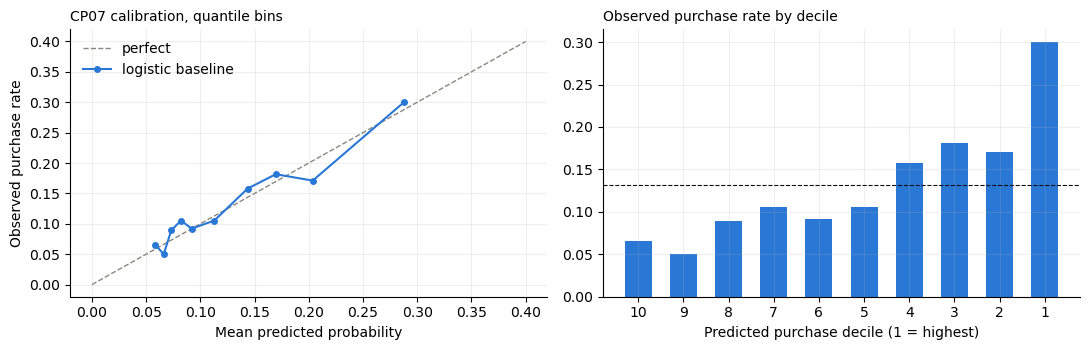

,n,purchase_rate,mean_pred,lift
decile,,,,
10,380,0.066,0.058,0.499
9,380,0.050,0.066,0.379
8,380,0.089,0.073,0.679
7,380,0.105,0.082,0.798
6,380,0.092,0.092,0.699
5,380,0.105,0.113,0.798
4,380,0.158,0.144,1.198
3,380,0.182,0.170,1.377
2,380,0.171,0.204,1.297


In [5]:
te = test[["assignment_id", "customer_id", "campaign_id", "purchase_14d"]].assign(predicted_purchase_probability=p_te)
te.to_csv(TABLES / "logistic_test_predictions.csv", index=False)
te["decile"] = pd.qcut(te.predicted_purchase_probability.rank(method="first"), 10, labels=range(10, 0, -1))
lift = te.groupby("decile", observed=True).agg(n=("purchase_14d", "size"), purchase_rate=("purchase_14d", "mean"),
                                             mean_pred=("predicted_purchase_probability", "mean")).sort_index()
lift["lift"] = lift.purchase_rate / te.purchase_14d.mean()
lift.to_csv(TABLES / "logistic_test_decile_lift.csv")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
limit = .4
ax[0].plot([0, limit], [0, limit], color="#898781", lw=1, ls="--", label="perfect")
observed, predicted = calibration_curve(yte, p_te, n_bins=10, strategy="quantile")
ax[0].plot(predicted, observed, marker="o", ms=4, lw=1.5, color="#2a78d6", label="logistic baseline")
frame = pd.DataFrame({"prediction": p_te, "purchase": yte})
frame["band"] = pd.qcut(frame.prediction, q=min(10, frame.prediction.nunique()), labels=False, duplicates="drop")
bins = frame.groupby("band", observed=True).agg(n=("purchase", "size"),
    mean_predicted_probability=("prediction", "mean"), observed_purchase_rate=("purchase", "mean")).reset_index()
bins.assign(model="logistic_baseline", split="CP07", binning="prediction quantiles; descriptive").to_csv(
    TABLES / "purchase_probability_calibration.csv", index=False)
ax[0].set_xlabel("Mean predicted probability"); ax[0].set_ylabel("Observed purchase rate")
ax[0].legend(frameon=False); ax[0].set_title("CP07 calibration, quantile bins", loc="left", fontsize=10)
ax[1].bar(lift.index.astype(str), lift.purchase_rate, color="#2a78d6", width=.6)
ax[1].axhline(te.purchase_14d.mean(), color="#0b0b0b", lw=.8, ls="--")
ax[1].set_xlabel("Predicted purchase decile (1 = highest)")
ax[1].set_title("Observed purchase rate by decile", loc="left", fontsize=10)
for a in ax:
    a.spines[["top", "right"]].set_visible(False); a.grid(alpha=.2)
fig.tight_layout(); fig.savefig(FIGS / "05_logistic_calibration_lift.png", bbox_inches="tight"); plt.show()
lift.round(3)


## Model interpretation and July scoring artifact
Coefficients are conditional associations on standardized numeric features, missing-value indicators, and one-hot category features; correlated predictors prevent interpreting them as causal effects. After evaluation, refit the same original specification on CP01-CP07 for July scoring. This final fit uses CP07 labels only after evaluation and is not used to report CP07 performance. Save just one deployment artifact: `logistic_propensity_model.joblib`.


In [6]:
base = getattr(model, "base", model)
coef = pd.Series(base.named_steps["lr"].coef_[0], index=base.named_steps["pre"].get_feature_names_out()).sort_values()
coef.rename("coefficient").to_csv(TABLES / "logistic_coefficients.csv")
display(pd.concat([coef.head(8), coef.tail(8)]).round(3).to_frame("coefficient"))
final = fit_logistic_baseline(df, NUM, CAT)
joblib.dump(final, MODELS / "logistic_propensity_model.joblib")
final_base = getattr(final, "base", final)
spec = {"model": "logistic_baseline", "target": "purchase_14d", "C": CONFIG["C"], "configuration": CONFIG,
        "numeric_features": NUM, "categorical_features": CAT,
        "encoded_features": final_base.named_steps["pre"].get_feature_names_out().tolist(),
        "train_campaigns_final": sorted(df.campaign_id.unique()),
        "validation_campaigns": ["CP04", "CP05", "CP06"],
        "evaluation_fit_campaigns": sorted(development.campaign_id.unique()),
        "evaluation_campaigns": ["CP07"], "evaluation_status": "retrospective; CP07 was previously inspected",
        "specification": "original", "implementation": "src.modeling.fit_logistic_baseline",
        "configuration_source": "config/logistic_baseline.json; user preference for the original baseline",
        "selection_rule": selection["selection_rule"], "f1_threshold_from_valid": F1_THR,
        "headline_metrics": ["average_precision", "recall"], "threshold_selection": threshold_metadata,
        "probability_interpretation": "purchase under historical treatment mixture, not untreated purchase probability"}
(MODELS / "logistic_model_features.json").write_text(json.dumps(spec, indent=2), encoding="utf-8")
reloaded = joblib.load(MODELS / "logistic_propensity_model.joblib")
np.testing.assert_allclose(reloaded.predict_proba(test[X_COLS]), final.predict_proba(test[X_COLS]))
assert np.isfinite(res[["average_precision", "recall", "roc_auc", "log_loss", "brier"]].values).all()
print(f"Saved + reloaded one logistic baseline: {len(X_COLS)} raw predictors -> {len(spec['encoded_features'])} encoded features")


Saved + reloaded one logistic baseline: 43 raw predictors -> 85 encoded features


,coefficient
cat__customer_tier_Standard,-0.637
num__missingindicator_days_since_last_session,-0.153
num__missingindicator_days_since_last_email_click,-0.102
cat__preferred_category_Accessories,-0.078
cat__top_category_viewed_30d_Accessories,-0.065
cat__preferred_category_Footwear,-0.063
cat__acquisition_channel_Affiliate,-0.054
num__days_since_last_email_click,-0.046
num__observed_units_purchased_90d,0.050
num__observed_prior_order_count,0.053
